# Side-specific projection and paired computational effects


Level 4. Prerequisites: all three preceding lessons and a completed frozen experimental export. Reading time: 40 minutes.

**Question:** Does the asymmetric projection's smaller original formulation meet the registered end-to-end improvement criterion against the faster matched baseline on held-out inputs?

## Objectives

A computational proposal must survive a comparison that could reject it. The candidate changes the side-specific interval proximal operation while keeping the principal OSQP system in the original variable dimension. That structural observation motivates an engineering hypothesis; it is not evidence that a wall-clock endpoint improves. Validation cost, dense preparation, iteration counts and backend maturity may overturn an argument based only on matrix size.

We will run the methods on a development problem, inspect their original KKT relations, examine a conditioning change and recompute the frozen held-out endpoint. The held-out seeds were registered before generation. This notebook does not choose a favorable subset or retune the candidate after viewing results. Its conclusion will distinguish a bounded implementation measurement from mathematical novelty, practitioner adoption and release acceptance.


## Setup

Use a separate Python 3.12 environment. The native engine is a separate distribution. Install the exact environment outside the notebook:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

The single setup cell resolves the repository, imports the methods and prints numerical versions. No installation runs inside a kernel.


In [1]:
# Resolve inputs once so every scientific cell focuses on the optimization.
from pathlib import Path
import sys
import json
import importlib.metadata
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
from softqp.flex import solve_flex
from softqp.elasti import solve_elastiqp
from softqp.sessions import PreparedSolver
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
from pipeline.softqp_campaign import generated_problem, primary_endpoint
from pipeline.optimality import kkt
from pipeline.control import predict_states
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Data

The executable development example uses seed 1000, n=32, density 0.05, condition one and asymmetric elastic costs. The registered campaign separately spans six held-out seeds, n=32/64/128/256, two densities, two diagonal conditions and three penalty families. Seven measured repetitions follow a warm-up for each backend and instance. Method order is randomized within each paired repetition.

Read the complete raw JSONL observations once. Warm-ups, incompatibilities, failures and resource limits remain present. The endpoint function applies its registered filter; the notebook does not discard rows before handing them to that function. The source inventory and artifact hashes are checked by the product's export verifier, independently of this lesson.


Provenance: Felipe Santibáñez-Leal authored the generator `data-pipeline/pipeline/softqp_campaign.py` (MIT code, https://github.com/fsantibanezleal/CAOS_SoftQP). The inputs are designed synthetic QPs, not measured plant data. The protocol `docs/design/experiments-v1.json` declares their population. The manifest `data/derived/experiments/campaign.json` and journal `trials.jsonl` hold numerical results published with the CC BY 4.0 report, https://doi.org/10.5281/zenodo.23851659. Backend software licences remain separate; possessing an output does not confer rights to a third-party dataset.


In [2]:
# Retain the complete denominator before applying the registered endpoint.
campaign = json.loads((root / "data/derived/experiments/campaign.json").read_text(encoding="utf-8"))
trial_file = root / "data/derived/experiments/trials.jsonl"
trials = [json.loads(line) for line in trial_file.read_text(encoding="utf-8").splitlines()]
protocol = campaign["protocol"]
print("Held-out seeds:", protocol["seeds"]["heldout"])
print("Raw observations including warm-ups:", len(trials))


Held-out seeds: [9000, 9001, 9002, 9003, 9004, 9005]
Raw observations including warm-ups: 21888


## Method

Begin with an actual solve at development scale. The extension supports nonnegative side-specific linear/quadratic prices and a fixed hard mask. Its asymmetric scalar proximal update follows convex interval-penalty minimization. The ordinary ADMM system still couples the variables, so rowwise shrinkage does not mean the entire QP decomposes into independent scalar decisions. Adaptive numerical rho can still trigger refactorization; preserving matrix dimensions is not a promise of one factorization forever.

Use equal absolute and relative tolerances for the following matched calls. These educational solves inspect correctness; their fresh wall times are deliberately not used to replace the preregistered campaign measurements.


### Deriving the side-specific proximal operation

Let a row value be $z=(Ax)_i$, with a preferred interval $[\ell,u]$. Its lower and upper departures are $d_L=(\ell-z)_+$ and $d_U=(z-u)_+$, where $(v)_+=\max(v,0)$. The coefficients $a_L,a_U$ have objective-unit per row-unit, while $b_L,b_U$ have objective-unit per squared row-unit. With all four coefficients nonnegative, the row cost is convex:

$$g(z)=a_Ld_L+a_Ud_U+\tfrac12 b_Ld_L^2+\tfrac12 b_Ud_U^2.$$

The native step does not first solve a hard problem and then repair an answer. It minimizes the row cost jointly with a positive metric displacement. For temporary row value $v$ and metric $h>0$, the local operation is

$$p_h(v)=\arg\min_z\{g(z)+\tfrac12h(z-v)^2\}.$$

Inside the preferred interval, $p_h(v)=v$: the row cost is already zero and moving would increase displacement. Above $u$, set $z=u+d$. The derivative becomes $(h+b_U)d+a_U-h(v-u)$. A nonnegative derivative at $d=0$ makes the endpoint optimal. Otherwise the positive root is the unique minimizer. Reflecting this argument below $\ell$ gives the other branch:

$$p_h(v)=\begin{cases}\ell-\dfrac{[h(\ell-v)-a_L]_+}{h+b_L},&v<\ell,\\v,&\ell\le v\le u,\\u+\dfrac{[h(v-u)-a_U]_+}{h+b_U},&v>u.\end{cases}$$

The linear price creates an endpoint sticking region; the quadratic price controls the slope after departure begins. A row marked hard instead uses the interval indicator and ordinary clipping. A very large finite price is not that indicator. An absent side contributes no price and no fictitious infinite-times-zero arithmetic. These branches and their implementation are derived in the [research manuscript](https://doi.org/10.5281/zenodo.23875071), within the proximal framework of [Parikh and Boyd](https://doi.org/10.1561/2400000003).

The global graph step still involves $P+S+A^\top H A$, with positive regularization $S$ and positive diagonal row metric $H$. Thus the simple local formula does not make a coupled QP separable. It preserves original row and variable counts, but factorization, memory layout, stopping tolerances and the number of iterations still matter. The comparison below tests actual returned primal and dual vectors before discussing dimension.

A useful hand exercise is to set $h=1$, $u=1$, $v=3$, $a_U=0.5$, and $b_U=2$. The upper departure is $(2-0.5)/3=0.5$, hence the local output is $1.5$. Raising only $a_U$ to $2$ places the output at the endpoint. This is the proximal subproblem, not the optimum of the full development QP; conflating those two levels would bypass the coupling through $A$.

In [3]:
# This development instance is separate from every held-out evaluation seed.
spec = dict(n=32, density=0.05, seed=1000, family="asymmetric-elastic", condition=1)
problem = generated_problem(spec)
settings = dict(eps_abs=1e-8, eps_rel=1e-8, max_iter=200000)
native_settings = dict(settings, adaptive_rho_interval=25)
candidate = solve(problem, "asymmetric", **native_settings)
print("Candidate dimensions:", candidate["dimensions"])
print(f"Development objective: {candidate['metrics']['objective']:.8f}")


Candidate dimensions: {'variables': 32, 'rows': 64, 'nnz': 144}
Development objective: -84.75011385


A fair lifting comparator must use the compact formulation whenever symmetry permits it. This asymmetric example instead requires distinct finite-side slacks. The high-accuracy independent oracle uses stock OSQP, while the timed campaign's ordinary lift uses the same native fork as the candidate. That separation avoids confusing an implementation difference between two OSQP builds with a formulation advantage.


In [4]:
# Use an independent stock implementation for this correctness oracle.
lifted = solve(problem, "lifted", reference_backend="stock", **native_settings)
relative_gap = abs(candidate["metrics"]["objective"] - lifted["metrics"]["objective"])
relative_gap /= max(1.0, abs(lifted["metrics"]["objective"]))
reduction = 1 - candidate["dimensions"]["variables"] / lifted["dimensions"]["variables"]
print("Lifted dimensions:", lifted["dimensions"])
print(f"Primal-dimension reduction: {100 * reduction:.6f}%")
print(f"Normalized development objective gap: {relative_gap:.3e}")


Lifted dimensions: {'variables': 136, 'rows': 220, 'nnz': 547}
Primal-dimension reduction: 76.470588%
Normalized development objective gap: 4.599e-10


DAQP is a necessary comparator because side-specific soft costs already exist in its interface. The candidate cannot claim a new modeling capability merely because it supports unequal prices. The registered endpoint therefore compares against the faster paired observation from DAQP and native lifting, not whichever baseline happens to look slowest. Run DAQP now to inspect that same scientific objective on another algorithm.


In [5]:
# A pre-existing side-specific algorithm prevents a novelty claim based only on asymmetry.
daqp = solve(problem, "daqp", **native_settings)
print("DAQP dimensions:", daqp["dimensions"])
print(f"DAQP objective difference: {abs(daqp['metrics']['objective'] - lifted['metrics']['objective']):.3e}")


DAQP dimensions: {'variables': 32, 'rows': 64, 'nnz': 144}
DAQP objective difference: 3.492e-09


Audit the recovered primal and dual vectors, not only costs. For a convex problem, stationarity and membership in the interval-penalty subgradient, together with hard feasibility, characterize optimality under the applicable assumptions. The proximal fixed-point defect tests the subgradient relation at kinks without choosing an arbitrary derivative. This makes a false stationary point easier to detect than an objective comparison alone.


In [6]:
# The dual must match the declared penalty, not merely cancel a gradient.
for result in [candidate, lifted, daqp]:
    audit = kkt(problem, result["x"], result["y"])
    print(result["method"], f"stationarity {audit['normalized_stationarity']:.3e}",
          f"proximal {audit['normalized_proximal_defect']:.3e}",
          f"hard {audit['hard_violation']:.3e}")


asymmetric stationarity 8.255e-10 proximal 9.106e-09 hard 6.574e-10
lifted stationarity 6.609e-10 proximal 5.637e-10 hard 3.051e-11
daqp stationarity 9.720e-17 proximal 1.887e-15 hard 1.554e-15


## Comparison

Plot the representation sizes only after establishing matched semantics. DAQP also works without the ordinary lift's explicit slack expansion. Consequently, a candidate-size advantage relative to lifting says nothing by itself about superiority to the stronger baseline. This is why the primary endpoint uses the faster of both references for every paired observation.


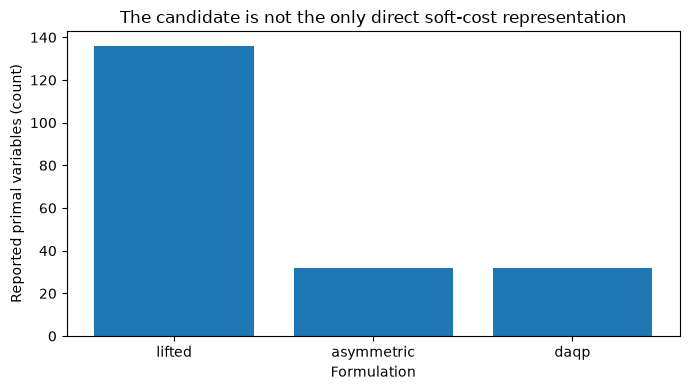

In [7]:
# Report mathematical dimensions without translating them into invented factor times.
results = [lifted, candidate, daqp]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([r["method"] for r in results], [r["dimensions"]["variables"] for r in results])
ax.set(xlabel="Formulation", ylabel="Reported primal variables (count)",
       title="The candidate is not the only direct soft-cost representation")
fig.tight_layout()
plt.show()


The ordinary lift has more explicit primal variables because it represents each priced side through auxiliary quantities. Both direct methods avoid that particular expansion. Their bars do not expose iteration work, numerical conditioning, Python validation overhead or active-set preparation. The figure therefore motivates a computational test rather than answering it, and it prevents a comparison that awards the candidate a unique capability already present in a published baseline.


### Sensitivity to conditioning and the limits of dimensional arguments

Change only the Hessian's diagonal condition while preserving the generator seed, sparse row matrix, preference vector, bounds and side prices. For each value, the notebook calls both real formulations afresh and compares their original objectives. This is a controlled instructional sensitivity experiment. It collects neither a timed observation nor another registered population member, and its four points are not independent draws from an application distribution.

The relative objective discrepancy uses $|J_c-J_l|/\max(1,|J_l|)$, where $c$ denotes the asymmetric path and $l$ the lifted path. Iteration count is displayed separately because it describes algorithmic work, not elapsed cost. A difficult problem can have small objective disagreement while requiring many more iterations. Conversely, a small discrepancy does not excuse a hard-row or dual-consistency failure. The earlier KKT checks and the separate hard-error printout remain necessary.

The condition parameter describes the diagonal $P$ used by this generator, not the condition number of every assembled KKT matrix. Row normalization and numerical scaling can change the latter. The displayed sensitivity therefore supports a narrow causal statement about this fixed authored family; it cannot identify the fastest backend on every sparse control workload.

1 gap 4.599e-10 hard 6.574e-10
100 gap 1.834e-09 hard 6.028e-13
10000 gap 3.318e-10 hard 2.170e-14
1000000 gap 2.564e-09 hard 1.110e-16


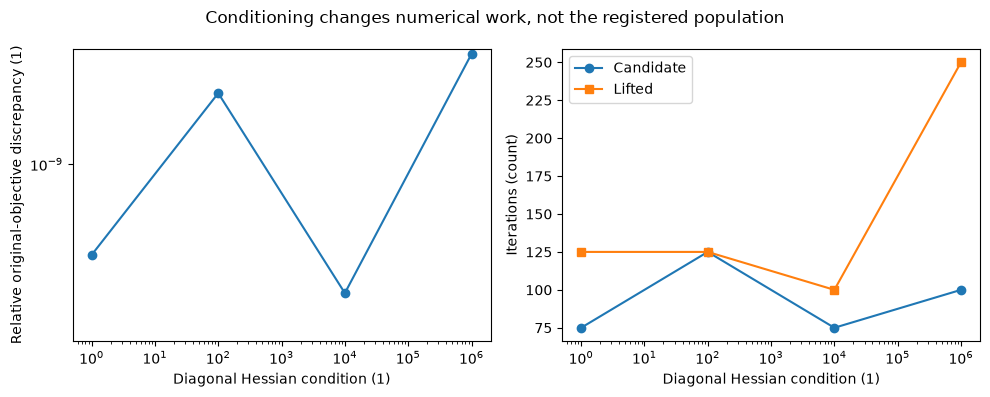

In [8]:
# Hold the seed and all non-Hessian inputs fixed; do not collect wall times.
conditions = [1, 100, 10000, 1000000]
sensitivity = []
for condition in conditions:
    difficult = generated_problem(dict(spec, condition=condition))
    difficult_native = solve(difficult, "asymmetric", **native_settings)
    difficult_lift = solve(difficult, "lifted", **native_settings)
    candidate_objective = difficult_native["metrics"]["objective"]
    reference_objective = difficult_lift["metrics"]["objective"]
    gap = abs(candidate_objective - reference_objective) / max(1.0, abs(reference_objective))
    sensitivity.append((gap, difficult_native["iterations"], difficult_lift["iterations"]))
    print(condition, f"gap {gap:.3e}", f"hard {difficult_native['metrics']['hard_violation']:.3e}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(conditions, [row[0] for row in sensitivity], marker="o")
axes[0].set(xscale="log", yscale="symlog",
            xlabel='Diagonal Hessian condition (1)',
            ylabel='Relative original-objective discrepancy (1)')
axes[0].set_yscale("symlog", linthresh=1e-12)
axes[1].plot(conditions, [row[1] for row in sensitivity], marker="o", label='Candidate')
axes[1].plot(conditions, [row[2] for row in sensitivity], marker="s", label='Lifted')
axes[1].set(xscale="log", xlabel='Diagonal Hessian condition (1)', ylabel='Iterations (count)')
axes[1].legend()
fig.suptitle('Conditioning changes numerical work, not the registered population')
fig.tight_layout()
plt.show()

The first panel reports the observed relative disagreement of the two objectives across the four Hessian settings; its symmetric-log scale preserves exact zero instead of replacing it with a made-up positive floor. The second reports the actual iteration counts returned by each solver. Their trends need not coincide. Neither panel measures runtime, and neither changes the registered timing conclusion. The loop also prints each hard-row error so that a visually small cost difference cannot hide an inadmissible physical result.

The largest relative discrepancy is about $2.6\times10^{-9}$. Native iteration counts range from 75 to 125, while the lifted formulation reaches 250 at condition one million. The lower native count at that endpoint is an algorithmic observation, not a measured time advantage.


## Evidence

The primary population is asymmetric elastic, n at least 128 and density 0.05. For each instance and repetition, reduction equals one minus candidate time divided by the faster matched baseline time. Negative values mean slower execution. The registered criterion requires at least 10% median reduction, a two-sided 95% seed-cluster bootstrap interval whose lower endpoint exceeds zero, and no failed compared pair. Whole seed clusters, rather than individual repetitions treated as independent experiments, are resampled.

Recompute that endpoint through the product's analysis method using every raw record. Missing or rejected pairs remain in its denominator. Import time, generation and export are outside the timed call; validation, formulation, setup, solve and original-space evaluation are inside. Isolated factorization time is not instrumented and cannot be reconstructed by subtracting unrelated timers.


In [9]:
# Recompute the registered statistic rather than selecting a favorable chart subset.
endpoint = primary_endpoint(trials, protocol)
print("Registered criterion:", endpoint["state"])
print("Accepted pairs / rejected pairs:", endpoint["paired_samples"], endpoint["rejected_pairs"])
print("Seed clusters:", endpoint["seed_clusters"])
if endpoint["median_relative_reduction"] is None:
    raise ValueError("Complete held-out experimental evidence is required")
print(f"Median relative reduction: {100 * endpoint['median_relative_reduction']:.3f}%")
print("95% interval (%):", [round(100 * x, 3) for x in endpoint["confidence_interval_95"]])


Registered criterion: not-established
Accepted pairs / rejected pairs: 168 0
Seed clusters: 6
Median relative reduction: 0.500%
95% interval (%): [-3.292, 3.945]


Display the registered effect and its seed-cluster interval with both the zero line and the practical target. Crossing zero means the direction is uncertain under this resampling scheme; failing to reach the 10% target is distinct from that uncertainty. A positive point estimate alone is insufficient. The visual also carries the sign convention explicitly so that a slower candidate cannot be presented as an improvement by reversing an axis.


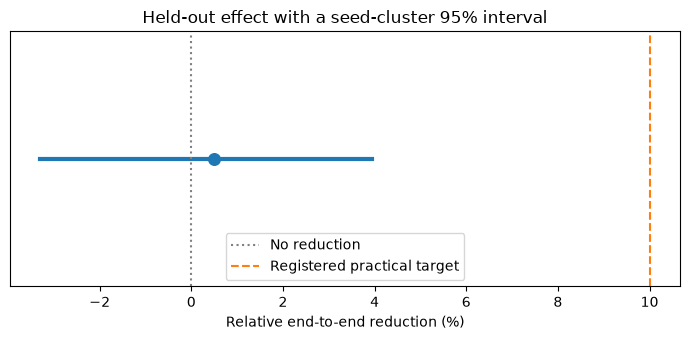

In [10]:
# The interval is descriptive of six seed clusters in this registered implementation regime.
estimate = 100 * endpoint["median_relative_reduction"]
low, high = [100 * x for x in endpoint["confidence_interval_95"]]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([low, high], [0, 0], linewidth=3)
ax.scatter([estimate], [0], s=70)
ax.axvline(0, color="gray", linestyle=":", label="No reduction")
ax.axvline(10, color="C1", linestyle="--", label="Registered practical target")
ax.set(xlabel="Relative end-to-end reduction (%)", yticks=[],
       title="Held-out effect with a seed-cluster 95% interval")
ax.legend()
fig.tight_layout()
plt.show()


This interval reflects repeated paired observations and variation across the registered seed clusters on one numerical environment. It does not cover every control model, machine, Hessian or implementation. The best-baseline comparison and the practical threshold were chosen before held-out generation, so their outcome remains meaningful even if it is unfavorable. Global algorithmic novelty, independent mathematical review and deployed-product acceptance are separate conclusions that this interval cannot establish.


### Use it on your own data

Start with a physical model, not with a target reduction percentage. The `Problem` interface accepts symmetric positive-semidefinite `P`, vector `q`, sparse `A`, interval vectors `lower` and `upper`, and a `Penalty` containing the four side-price arrays and the hard/soft mask. Their lengths must match rows; a lower bound cannot exceed its upper bound. A missing endpoint is infinity of the correct sign in memory and the documented null representation when encoded. Missing coefficients or results are not replaced by successful zeros. The case-spec schema records units and row identities so that an exported decision can be interpreted in original coordinates.

For a local study, construct that object through the existing case builder or decode a declared case-spec, then call `solve(problem, "asymmetric", **native_settings)`. Solve the same object with `"lifted"` and an independently built stock reference where supported. Compare original objective components, hard violations and `kkt(problem, x, y)` before any speed claim. If a backend refuses the declared penalty, retain the incompatibility and its reason. Do not replace elastic costs by pure L1 merely to obtain another row of successful numbers.

The campaign boundary and the trial boundary solve different problems. `softqp-campaign` stores the frozen protocol, environment, complete instance inventory, summary counts and source identities. Each `softqp-trial` journal row identifies `id`, `split`, `seed`, method, repetition, warm-up flag, state and elapsed scope; failed or incompatible rows remain records with reasons. The `(id, repetition)` pairing key binds methods to the same input. A missing method is a rejected pair, not permission to reduce the denominator. The export stage owns these documents; the browser's experiment view consumes only admitted summaries. This notebook reads the complete journal and calls the named analysis function once, without editing the journal or manifest.

For future research, register a separate protocol and fresh destination before collecting data. Specify hardware, thread count, warm-ups, random order, timeout, numerical acceptance and the practical target in advance. The existing protocol is historical evidence and is not a template to overwrite. A new customer objective or platform changes the external-validity question even if this proximal derivation remains applicable.

## Results

**Answer:** The candidate does not meet the registered criterion: median relative reduction 0.500%, 95% seed-cluster interval [-3.292%, 3.945%], 168 accepted pairs and 0 rejected pairs. This is a bounded implementation outcome, not proof of global novelty or operational safety.

In the executed development example, the candidate uses 32 variables versus 136 for explicit lifting, a 76.470588% reduction in reported primal dimension. DAQP's direct soft-cost representation shows why that count alone is not a comparative research result. The conclusion above uses the registered wall-clock scope and retains numerical acceptance, not the appearance of a favorable matrix-size plot.


## Summary

Separate a derivation, an implementation property and an empirical improvement. The proximal formula can be correct even when an endpoint fails, and an endpoint can improve without establishing a new mathematical idea. Preserve negative outcomes, narrow any successful claim to its measured regime and seek independent review before scientific promotion. A practitioner deciding whether to adopt the engine still needs representative workloads, platform validation and a justified hard/soft policy.


## References

- [Generalized slack projections](https://arxiv.org/abs/2610.35631).
- [DAQP side-specific soft constraints](https://darnstrom.github.io/daqp/start/advanced/soft).
- [OSQP solver and stopping conditions](https://osqp.org/docs/solver/).
- Frozen protocol: `docs/design/experiments-v1.json`; complete original observations and campaign manifest under `data/derived/experiments/`.

- [Proximal Algorithms, Parikh and Boyd](https://doi.org/10.1561/2400000003).
- [Original-row research manuscript](https://doi.org/10.5281/zenodo.23875071).
